# 기업의 고용과 수익성 분석

**합성 데이터 실행 예제 — 실제 기업에 대한 분석 성과가 아닙니다.**

원본 수업 프로젝트의 데이터 정합성·누수 문제를 수정한 파이프라인을 설명합니다. 저장소 루트에서 `uv sync --locked`를 실행한 환경으로 이 노트북을 엽니다.

## 1. 질문과 분석 범위

전년도 재무정보가 다음 해 적자 여부를 구분하는지, 직원수 정보를 추가하면 도움이 되는지 비교합니다. 같은 해 손익을 입력해 같은 해 흑자를 맞히지 않습니다. 공시 시점과 정정 이력을 복원하지 않았으므로 실제 시점 백테스트는 아닙니다.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from data_final.analysis import run_analysis
from data_final.data import build_examples, quality_summary, synthetic_panel

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
panel = synthetic_panel(seed=42)
quality_summary(panel)

{'rows': 700,
 'companies': 100,
 'years': [2018, 2019, 2020, 2021, 2022, 2023, 2024],
 'data_kind': 'synthetic',
 'missing_fraction': {'revenue': 0.0,
  'operating_income': 0.024285714285714285,
  'net_income': 0.025714285714285714,
  'assets': 0.0,
  'liabilities': 0.0,
  'employees': 0.03428571428571429},
 'missing_net_income': 18,
 'zero_net_income': 0,
 'scope': 'annual OFS; amounts in source currency KRW; employee headcount'}

## 2. 입력과 타깃을 분리하기

회사 고유번호와 연도로 유일성을 검증합니다. 결측 타깃은 채우지 않고 제외합니다. t년 변수와 t+1년 타깃을 연결하고, 연속 연도만 성장률을 계산합니다.

In [2]:
examples = build_examples(panel)
examples[
    ["corp_code", "year", "target_year", "net_margin", "employee_growth", "loss_next_year"]
].head(8)

,corp_code,year,target_year,net_margin,employee_growth,loss_next_year
0,90000000,2018,2019,-0.043688,NaN,0
1,90000000,2019,2020,0.078911,-0.012064,1
2,90000000,2020,2021,-0.027528,-0.013908,1
3,90000000,2021,2022,-0.018627,0.031304,1
4,90000000,2022,2023,-0.030458,0.066711,0
5,90000000,2023,2024,0.212413,0.043777,0
6,90000001,2018,2019,-0.037180,NaN,0
7,90000001,2019,2020,0.016420,-0.027172,0


## 3. 과거 연도에서 모델과 피처 구성 선택

매 fold의 과거 데이터에서만 결측값 대체와 스케일링을 학습합니다. financial과 financial_employment를 같은 모델 안에서 비교합니다. 최종 연도는 모델 선택에 사용하지 않으며 임계값은 0.5로 고정합니다.

In [3]:
OUT = ROOT / "reports" / "runs" / "notebook"
result = run_analysis(panel, OUT, test_year=2024, seed=42)
pd.read_csv(OUT / "model_comparison.csv")

,model,features,mean_validation_ap,std_validation_ap,mean_validation_auc,folds
0,hist_gradient_boosting,financial,0.672026,0.085247,0.681294,3
1,logistic,financial,0.648100,0.117902,0.692835,3
2,hist_gradient_boosting,financial_employment,0.638114,0.090808,0.663995,3
3,logistic,financial_employment,0.631349,0.136724,0.679797,3
4,dummy,financial,0.444910,0.055527,0.500000,3


## 4. 최종 평가와 단순 기준 비교

양성 클래스는 적자입니다. 정확도뿐 아니라 적자 재현율·AP·ROC-AUC를 확인합니다. 전년 손익 유지와 학습 적자비율을 기준으로 비교합니다. 아래 수치는 합성 데이터에서만 의미가 있습니다.

In [4]:
pd.DataFrame({"selected": result["metrics"], **result["baselines"]}).T

,n,loss_prevalence,accuracy,balanced_accuracy,loss_precision,loss_recall,loss_f1,roc_auc,average_precision,brier
selected,97.0,0.453608,0.701031,0.693611,0.692308,0.613636,0.650602,0.731561,0.669336,0.213543
training_class_prior,97.0,0.453608,0.546392,0.500000,0.000000,0.000000,0.000000,0.500000,0.453608,0.250380
previous_year_loss,97.0,0.453608,0.659794,0.659734,0.617021,0.659091,0.637363,0.653302,0.561312,0.343560


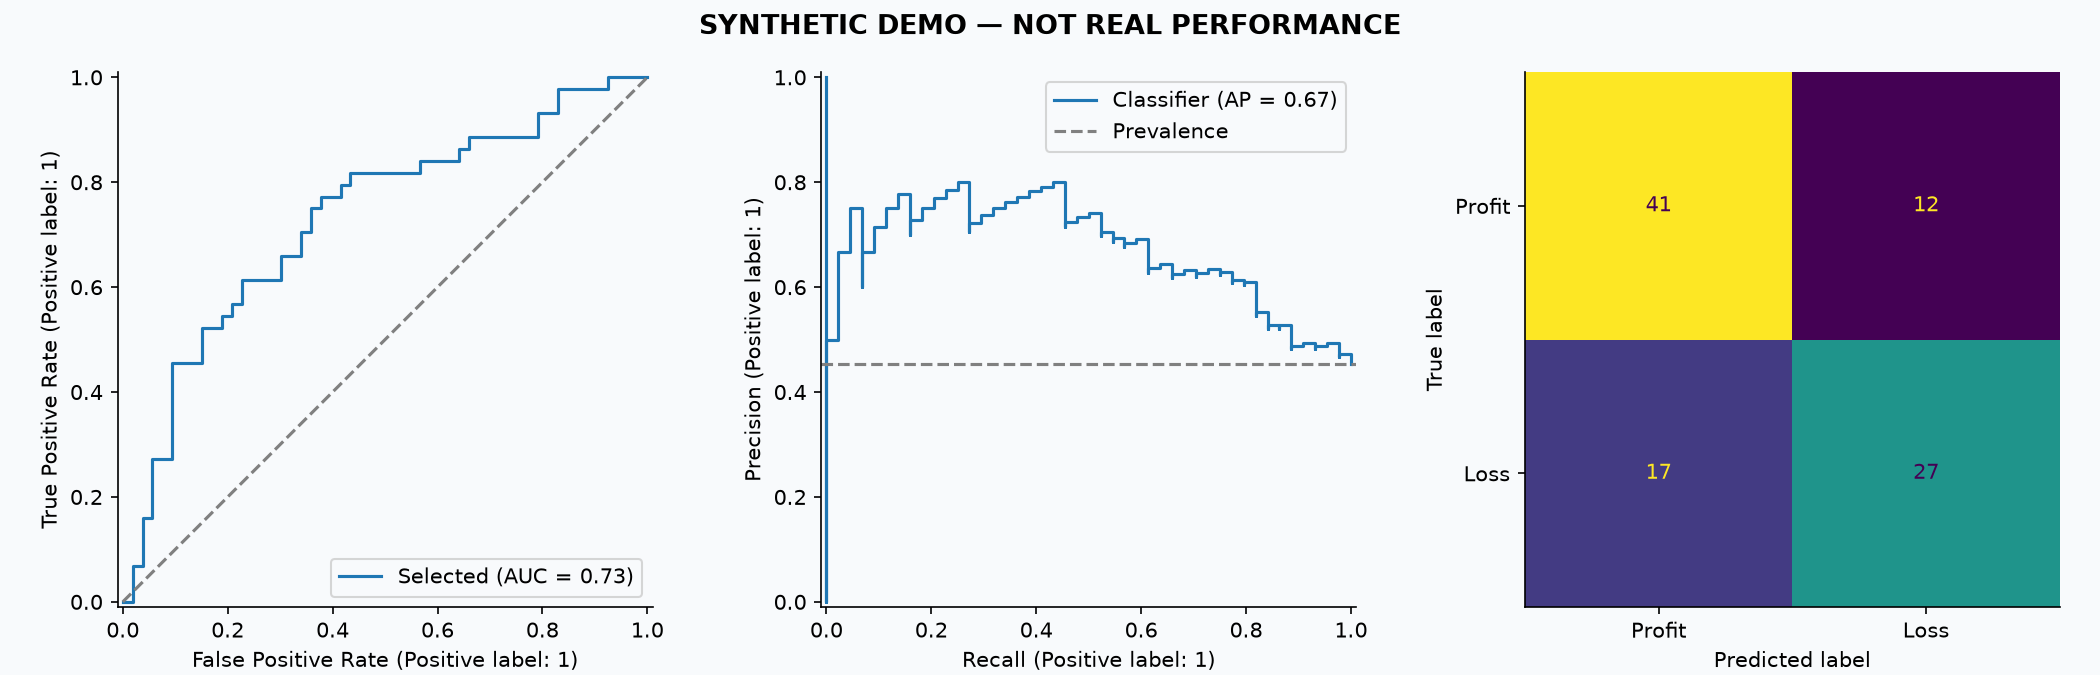

In [5]:
display(Image(filename=str(OUT / "evaluation.png")))

## 5. 불확실성과 설명

Bootstrap 구간은 이 모델과 이 테스트 연도에 조건부인 구간입니다. 연도 간 충격이나 학습 변화까지 반영하지 않습니다. 중요도는 인과 효과가 아니며 상관된 피처 사이에 분산될 수 있습니다.

In [6]:
result["bootstrap_95_percent_intervals"]

{'roc_auc': [0.6361385077186964, 0.8235956260720411],
 'average_precision': [0.5708191308840616, 0.8098454048736016],
 'loss_recall': [0.45454545454545453, 0.75]}

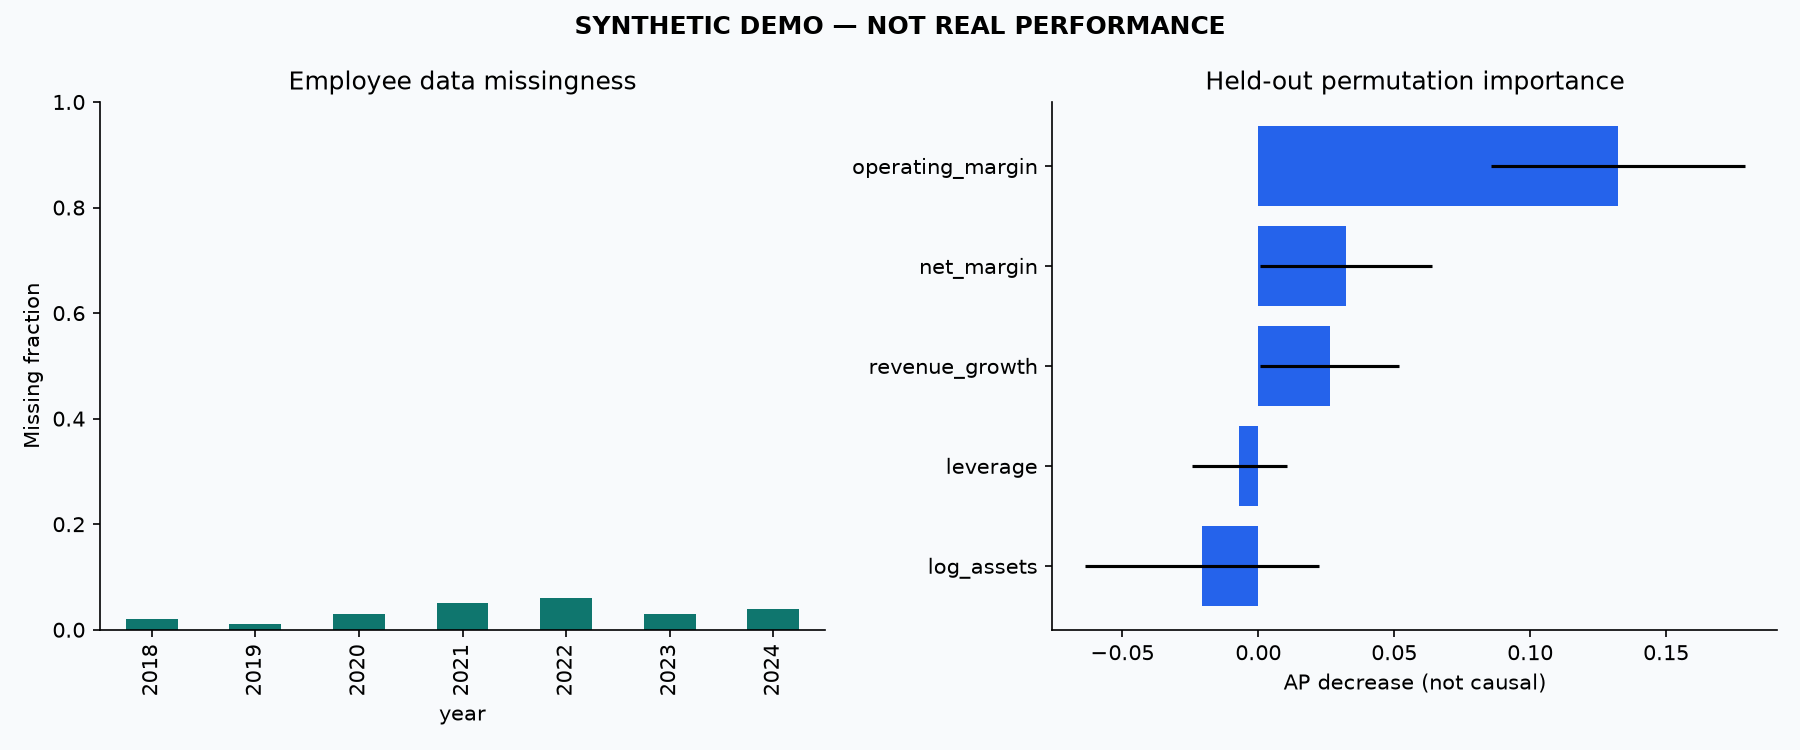

In [7]:
display(Image(filename=str(OUT / "quality_importance.png")))

## 6. 고용·수익 변화의 관련성

기업 규모 영향을 일부 줄이기 위해 직원수 변화율과 순이익 변화/전기 자산을 비교합니다. 연도별 완전 관측 쌍만 사용하며, 인과관계나 대표성을 주장하지 않습니다.

In [8]:
pd.read_csv(OUT / "employment_correlations.csv")

,year,n_complete_pairs,pearson_r,spearman_r
0,2019,94,-0.004244,0.001033
1,2020,92,0.057418,0.062790
2,2021,89,0.047100,0.002434
3,2022,82,0.050937,0.063027
4,2023,84,-0.129960,-0.144215
5,2024,88,-0.111586,-0.125374


## 7. 실데이터로 넘어가기

1. 선정 기준이 명확한 기업 모집단을 구성합니다.
2. 새 DART 키로 수집하고 계정 매핑·직원수 집계를 원문과 대조합니다.
3. `data-final validate`와 `data-final analyze`를 실행합니다.
4. 실제 검증 결과, 실패 사례, 공시 시점·생존편향 한계를 기록합니다.

**지금 말할 수 있는 성과는 재현 가능한 시스템 구현과 실행 검증입니다. 실제 기업 예측 성과는 아직 확정하지 않았습니다.**

참고: [방법론](../docs/methodology.md), [데이터 사전](../docs/data_dictionary.md), [포트폴리오 가이드](../docs/portfolio.md).